In [2]:
import os
import time
import copy
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch_pruning as tp
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

warnings.filterwarnings("ignore")

LOG_DIR = "logs/llm_pruning"
os.makedirs(LOG_DIR, exist_ok=True)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"Log dir: {os.path.abspath(LOG_DIR)}")

/home/user/projects/Quantization-and-Pruning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Log dir: /home/user/projects/Quantization-and-Pruning/pruning/logs/llm_pruning


In [3]:
MODEL_ID = "HuggingFaceTB/SmolLM-135M"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token


def load_fresh_model():
    m = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.float16,
        device_map="auto" if device.type == "cuda" else None,
    )
    m.eval()
    return m


_probe = load_fresh_model()
print(f"Params: {sum(p.numel() for p in _probe.parameters()):,}")
print(f"Heads: {_probe.config.num_attention_heads} | "
      f"KV heads: {_probe.config.num_key_value_heads}")
print(f"Layers: {_probe.config.num_hidden_layers} | "
      f"Intermediate: {_probe.config.intermediate_size}")
del _probe
if device.type == "cuda":
    torch.cuda.empty_cache()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 272/272 [00:00<00:00, 3356.41it/s]

Params: 134,515,008
Heads: 9 | KV heads: 3
Layers: 30 | Intermediate: 1536


In [4]:
dataset = load_dataset("wikitext", "wikitext-2-raw-v1")
test_texts = [t for t in dataset["test"]["text"] if len(t.strip()) > 0]
print(f"Test samples: {len(test_texts)}")

Using the latest cached version of the dataset since wikitext couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'wikitext-2-raw-v1' at /home/user/.cache/huggingface/datasets/wikitext/wikitext-2-raw-v1/0.0.0/b08601e04326c79dfdd32d625aee71d232d685c3 (last modified on Fri Aug 28 13:04:59 2026).


Test samples: 2891


In [5]:
@torch.no_grad()
def evaluate_perplexity(model, tokenizer, texts, max_length=512, stride=256):
    model.eval()
    encodings = tokenizer("\n\n".join(texts), return_tensors="pt")
    input_ids = encodings.input_ids.to(model.device)

    nlls = []
    prev_end = 0
    for begin in range(0, input_ids.size(1), stride):
        end = min(begin + max_length, input_ids.size(1))
        trg_len = end - prev_end

        chunk = input_ids[:, begin:end]
        targets = chunk.clone()
        targets[:, :-trg_len] = -100

        outputs = model(chunk, labels=targets)
        nlls.append(outputs.loss * trg_len)

        prev_end = end
        if end == input_ids.size(1):
            break

    ppl = torch.exp(torch.stack(nlls).sum() / end).item()
    return ppl

In [6]:
example_inputs = tokenizer("Hello world", return_tensors="pt").to(device)
forward_fn = lambda model, inputs: model(**inputs).logits


def iterative_prune(model, target_ratio, steps=5):
    m = copy.deepcopy(model)
    m.eval()

    ignored = [m.lm_head, m.model.embed_tokens]

    # GQA: не трогаем attention-проекции
    if m.config.num_attention_heads != m.config.num_key_value_heads:
        for layer in m.model.layers:
            ignored.extend([
                layer.self_attn.q_proj,
                layer.self_attn.k_proj,
                layer.self_attn.v_proj,
                layer.self_attn.o_proj,
            ])

    pruner = tp.pruner.MagnitudePruner(
        m,
        example_inputs,
        importance=tp.importance.MagnitudeImportance(p=2),
        global_pruning=True,
        pruning_ratio=target_ratio,
        iterative_steps=steps,
        ignored_layers=ignored,
        forward_fn=forward_fn,  
    )

    for step in range(steps):
        pruner.step()

    return m

In [7]:
PRUNING_RATIOS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
STEPS = 5

all_rows = []

for ratio in PRUNING_RATIOS:
    print(f"\n=== ratio={ratio} ===")

    try:
        base = load_fresh_model()

        if ratio == 0.0:
            pruned = base
        else:
            pruned = iterative_prune(base, ratio, steps=STEPS)
            del base
            if device.type == "cuda":
                torch.cuda.empty_cache()

        n_params = sum(p.numel() for p in pruned.parameters())
        model_size_mb = n_params * 2 / (1024 ** 2)

        # Сброс счётчика памяти перед инференсом
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats()

        t0 = time.perf_counter()
        ppl = evaluate_perplexity(pruned, tokenizer, test_texts)
        eval_time_s = time.perf_counter() - t0

        peak_mem_mb = (
            torch.cuda.max_memory_allocated() / (1024 ** 2)
            if device.type == "cuda" else 0.0
        )

        all_rows.append({
            "ratio": ratio,
            "params": n_params,
            "model_size_mb": model_size_mb,
            "peak_mem_mb": peak_mem_mb,
            "ppl": ppl,
            "eval_time_s": eval_time_s,
            "error": "",
        })

        print(f"  params={n_params:,}  size={model_size_mb:.1f} MB  "
              f"peak_mem={peak_mem_mb:.1f} MB  ppl={ppl:.2f}  "
              f"eval={eval_time_s:.1f}s")

        del pruned
        if device.type == "cuda":
            torch.cuda.empty_cache()

    except Exception as e:
        print(f"  FAILED: {type(e).__name__}: {e}")
        all_rows.append({
            "ratio": ratio, "params": np.nan, "model_size_mb": np.nan,
            "peak_mem_mb": np.nan, "ppl": np.nan,
            "eval_time_s": np.nan, "error": str(e),
        })
        if device.type == "cuda":
            torch.cuda.empty_cache()


=== ratio=0.0 ===


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1926.09it/s]


  params=134,515,008  size=256.6 MB  peak_mem=578.7 MB  ppl=18.38  eval=13.7s

=== ratio=0.1 ===


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 3439.18it/s]


  params=126,552,384  size=241.4 MB  peak_mem=726.4 MB  ppl=5893.11  eval=14.0s

=== ratio=0.2 ===


...

  params=110,625,408  size=211.0 MB  peak_mem=694.8 MB  ppl=21169.50  eval=14.1s

=== ratio=0.4 ===


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 3894.45it/s]


  params=102,664,512  size=195.8 MB  peak_mem=1049.6 MB  ppl=314822.19  eval=14.0s

=== ratio=0.5 ===


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 3647.10it/s]


  params=94,701,888  size=180.6 MB  peak_mem=666.7 MB  ppl=828641.94  eval=14.1s



✓ Saved: /home/user/projects/Quantization-and-Pruning/pruning/logs/llm_pruning/ppl_memory.csv
 ratio    params  model_size_mb  peak_mem_mb           ppl  eval_time_s error
   0.0 134515008     256.567017   578.694824     18.376352    13.695661      
   0.1 126552384     241.379517   726.379395   5893.112793    14.031060      
   0.2 118588032     226.188721   706.999023  17030.412109    13.803004      
   0.3 110625408     211.001221   694.815430  21169.498047    14.131761      
   0.4 102664512     195.817017  1049.628418 314822.187500    14.005408      
   0.5  94701888     180.629517   666.708984 828641.937500    14.147688      


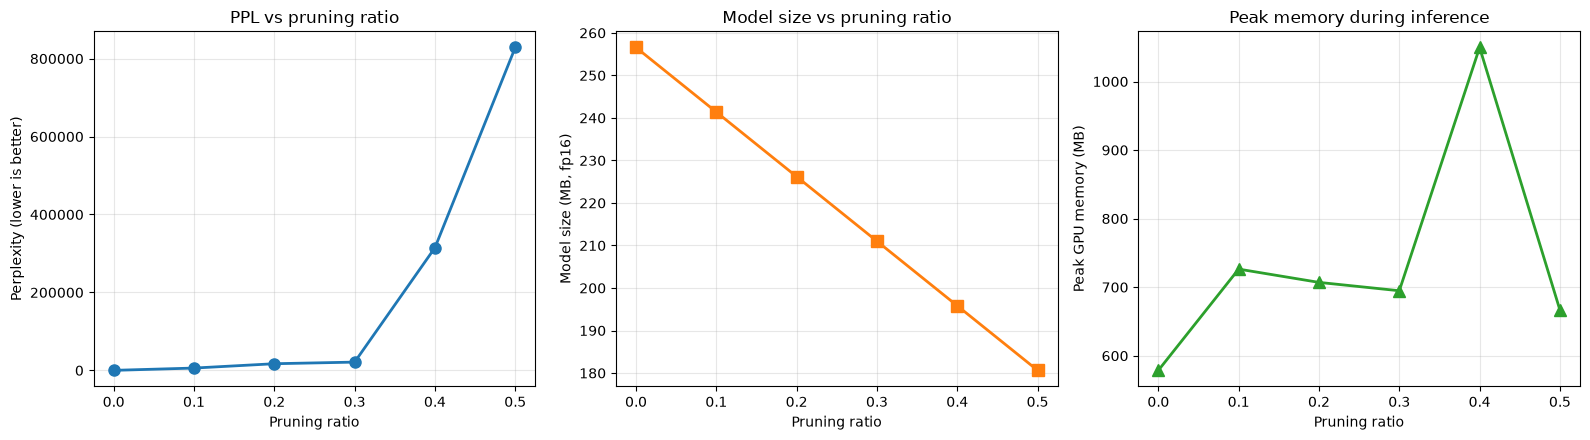

✓ Saved: logs/llm_pruning/ppl_memory_plots.png


In [8]:
df = pd.DataFrame(all_rows)
out_csv = os.path.join(LOG_DIR, "ppl_memory.csv")
df.to_csv(out_csv, index=False)
print(f"\n✓ Saved: {os.path.abspath(out_csv)}")
print(df.to_string(index=False))

df_ok = df.dropna(subset=["ppl"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# PPL
axes[0].plot(df_ok["ratio"], df_ok["ppl"], "o-", linewidth=2, markersize=8)
axes[0].set_xlabel("Pruning ratio")
axes[0].set_ylabel("Perplexity (lower is better)")
axes[0].set_title("PPL vs pruning ratio")
axes[0].grid(True, alpha=0.3)

# Model size
axes[1].plot(df_ok["ratio"], df_ok["model_size_mb"], "s-",
             linewidth=2, markersize=8, color="tab:orange")
axes[1].set_xlabel("Pruning ratio")
axes[1].set_ylabel("Model size (MB, fp16)")
axes[1].set_title("Model size vs pruning ratio")
axes[1].grid(True, alpha=0.3)

# Peak memory during inference
axes[2].plot(df_ok["ratio"], df_ok["peak_mem_mb"], "^-",
             linewidth=2, markersize=8, color="tab:green")
axes[2].set_xlabel("Pruning ratio")
axes[2].set_ylabel("Peak GPU memory (MB)")
axes[2].set_title("Peak memory during inference")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
out_png = os.path.join(LOG_DIR, "ppl_memory_plots.png")
plt.savefig(out_png, dpi=150, bbox_inches="tight")
plt.show()
print(f"✓ Saved: {out_png}")